In [8]:
from konlpy.tag import Okt, Hannanum, Kkma, Komoran
import pandas as pd
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import re

# 형태소 분석기

In [3]:
okt = Okt()

In [4]:
print(okt.pos("아버지가 방에 들어가신다"))

[('아버지', 'Noun'), ('가', 'Josa'), ('방', 'Noun'), ('에', 'Josa'), ('들어가신다', 'Verb')]


In [5]:
print(okt.morphs("아버지가 방에 들어가신다"))

['아버지', '가', '방', '에', '들어가신다']


In [6]:
print(okt.morphs("아버지가 방에 들어가신다", stem = True))

['아버지', '가', '방', '에', '들어가다']


In [7]:
print(okt.nouns("아버지가 방에 들어가신다"))

['아버지', '방']


In [15]:
print(okt.pos("GDNTOPCLASSINTHECLUB"))

[('GDNTOPCLASSINTHECLUB', 'Alpha')]


In [9]:
kkma = Kkma()

In [11]:
print(kkma.pos("아버지가 방에 들어가신다"))

[('아버지', 'NNG'), ('가', 'JKS'), ('방', 'NNG'), ('에', 'JKM'), ('들어가', 'VV'), ('시', 'EPH'), ('ㄴ다', 'EFN')]


# 데이터 확인

In [26]:
train_df = pd.read_csv("./data/nsmc/ratings_train.txt", sep = "\t")
test_df = pd.read_csv('./data/nsmc/ratings_test.txt', sep = "\t")

In [27]:
train_df.head()

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


In [28]:
test_df.head()

,id,document,label
0,6270596,굳 ㅋ,1
1,9274899,GDNTOPCLASSINTHECLUB,0
2,8544678,뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아,0
3,6825595,지루하지는 않은데 완전 막장임... 돈주고 보기에는....,0
4,6723715,3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??,0


In [29]:
train_df.shape, test_df.shape

((150000, 3), (50000, 3))

In [30]:
train_df.isna().sum()

id          0
document    5
label       0
dtype: int64

In [31]:
test_df.isna().sum()

id          0
document    3
label       0
dtype: int64

In [32]:
train_df = train_df.dropna(subset = ["document"])
test_df = test_df.dropna(subset = ["document"])

In [33]:
train_df.shape, test_df.shape

((149995, 3), (49997, 3))

In [34]:
# 종속변수 확인
np.unique(train_df["label"], return_counts = True)

(array([0, 1], dtype=int64), array([75170, 74825], dtype=int64))

# 데이터 전처리

In [37]:
# 한글 이외의 문자들 제거
train_df["document"] = train_df["document"].str.replace("[^ㄱ-ㅎㅏ-ㅣ가-힣 ]", "", regex = True)
test_df["document"] = test_df["document"].str.replace("[^ㄱ-ㅎㅏ-ㅣ가-힣 ]", "", regex = True)

In [38]:
train_df.head()

,id,document,label
0,9976970,아 더빙 진짜 짜증나네요 목소리,0
1,3819312,흠포스터보고 초딩영화줄오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 솔직히 재미는 없다평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화스파이더맨에서 늙어보이기만 했던 커스틴 던...,1


In [39]:
test_df.head()

,id,document,label
0,6270596,굳 ㅋ,1
1,9274899,,0
2,8544678,뭐야 이 평점들은 나쁘진 않지만 점 짜리는 더더욱 아니잖아,0
3,6825595,지루하지는 않은데 완전 막장임 돈주고 보기에는,0
4,6723715,만 아니었어도 별 다섯 개 줬을텐데 왜 로 나와서 제 심기를 불편하게 하죠,0


In [41]:
len(test_df.iloc[1, 1])

0

In [42]:
# document 컬럼이 비어있는 경우 삭제
train_df = train_df[train_df["document"].map(lambda x: len(x.strip()) >= 1)]
test_df = test_df[test_df["document"].map(lambda x: len(x.strip()) >= 1)]

In [43]:
train_df.shape, test_df.shape

((148740, 3), (49575, 3))

In [44]:
# 중복 데이터 확인
train_df[train_df["document"].duplicated(keep = False)].sort_values("document")

,id,document,label
46599,9682597,그리고 내 감정을 불러 일으켰다,1
43436,9582856,그리고 내 감정을 불러 일으켰다,1
123713,9582855,그리고 내 감정을 불러 일으켰다,1
93364,171409,가입 추천바람,1
138373,171407,가입 추천바람,1
...,...,...,...
57831,3906478,흥미진진,1
8446,5158304,힐러리 더프의 매력에 빠지다,1
72688,5153363,힐러리 더프의 매력에 빠지다,1
26889,7971814,힘들다,0


In [45]:
# 중복 제거
train_df = train_df.drop_duplicates(subset = ["document"])
test_df = test_df.drop_duplicates(subset = ["document"])

In [46]:
train_df.shape, test_df.shape

((143660, 3), (48403, 3))

# 토큰화

In [47]:
%%time
train_df["token"] = train_df["document"].map(lambda x: okt.morphs(x, stem = True))
test_df["token"] = test_df["document"].map(lambda x: okt.morphs(x, stem = True))

CPU times: total: 14min 17s
Wall time: 13min 39s


In [48]:
train_df.to_csv("./data/nsmc_ratings_train_pre.csv", index = False)
test_df.to_csv("./data/nsmc_ratings_test_pre.csv", index = False)

In [ ]:
train_df = pd.read_csv("./data/nsmc_ratings_train_pre.csv")
test_df = pd.read_csv("./data/nsmc_ratings_test_pre.csv")

train_df["token"] = train_df["token"].map(lambda x: eval(x))
test_df["token"] = test_df["token"].map(lambda x: eval(x))

In [49]:
train_df.head()

,id,document,label,token
0,9976970,아 더빙 진짜 짜증나네요 목소리,0,"[아, 더빙, 진짜, 짜증나다, 목소리]"
1,3819312,흠포스터보고 초딩영화줄오버연기조차 가볍지 않구나,1,"[흠, 포스터, 보고, 초딩, 영화, 줄, 오버, 연기, 조차, 가볍다, 않다]"
2,10265843,너무재밓었다그래서보는것을추천한다,0,"[너, 무재, 밓었, 다그, 래서, 보다, 추천, 한, 다]"
3,9045019,교도소 이야기구먼 솔직히 재미는 없다평점 조정,0,"[교도소, 이야기, 구먼, 솔직하다, 재미, 는, 없다, 평점, 조정]"
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화스파이더맨에서 늙어보이기만 했던 커스틴 던...,1,"[사이, 몬페, 그, 의, 익살스럽다, 연기, 가, 돋보이다, 영화, 스파이더맨, ..."


In [52]:
train_df = train_df[train_df["token"].map(lambda x: len(x) > 0)]
test_df = test_df[test_df["token"].map(lambda x: len(x) > 0)]

In [53]:
train_df.shape, test_df.shape

((143660, 4), (48403, 4))

# 정수인코딩

In [54]:
tokenizer = Tokenizer()

In [55]:
# 단어 집합 생성
# 등장 빈도 수가 높은 순서대로 정수값 부여
tokenizer.fit_on_texts(train_df["token"])

In [56]:
# 단어 집합
tokenizer.word_index

{'이': 1,
 '영화': 2,
 '보다': 3,
 '하다': 4,
 '의': 5,
 '에': 6,
 '가': 7,
 '을': 8,
 '도': 9,
 '들': 10,
 '는': 11,
 '를': 12,
 '은': 13,
 '없다': 14,
 '이다': 15,
 '있다': 16,
 '좋다': 17,
 '너무': 18,
 '다': 19,
 '정말': 20,
 '한': 21,
 '되다': 22,
 '적': 23,
 '만': 24,
 '재밌다': 25,
 '같다': 26,
 '진짜': 27,
 '으로': 28,
 '로': 29,
 '아니다': 30,
 '않다': 31,
 '점': 32,
 '에서': 33,
 '만들다': 34,
 '과': 35,
 '나오다': 36,
 '연기': 37,
 '것': 38,
 '평점': 39,
 '내': 40,
 '최고': 41,
 '그': 42,
 '나': 43,
 '안': 44,
 '인': 45,
 '스토리': 46,
 '생각': 47,
 '못': 48,
 '왜': 49,
 '드라마': 50,
 '게': 51,
 '사람': 52,
 '감동': 53,
 '보고': 54,
 '이렇다': 55,
 '고': 56,
 '말': 57,
 '아깝다': 58,
 '더': 59,
 '배우': 60,
 '때': 61,
 'ㅋㅋ': 62,
 '와': 63,
 '아': 64,
 '감독': 65,
 '거': 66,
 '그냥': 67,
 '요': 68,
 '재미있다': 69,
 '재미': 70,
 '시간': 71,
 '내용': 72,
 '까지': 73,
 '뭐': 74,
 '중': 75,
 '주다': 76,
 '좀': 77,
 '자다': 78,
 '하고': 79,
 '지루하다': 80,
 '수': 81,
 '재미없다': 82,
 '네': 83,
 '쓰레기': 84,
 '모르다': 85,
 '가다': 86,
 '들다': 87,
 '그렇다': 88,
 '싶다': 89,
 '지': 90,
 '작품': 91,
 '사랑': 92,
 '알다': 93,
 '하나': 94

In [57]:
# 단어 등장 수
tokenizer.word_counts

OrderedDict([('아', 4121),
             ('더빙', 572),
             ('진짜', 8288),
             ('짜증나다', 1002),
             ('목소리', 374),
             ('흠', 246),
             ('포스터', 572),
             ('보고', 4653),
             ('초딩', 422),
             ('영화', 50172),
             ('줄', 1240),
             ('오버', 142),
             ('연기', 6326),
             ('조차', 242),
             ('가볍다', 360),
             ('않다', 7718),
             ('너', 670),
             ('무재', 69),
             ('밓었', 1),
             ('다그', 75),
             ('래서', 20),
             ('보다', 40991),
             ('추천', 1180),
             ('한', 9615),
             ('다', 10077),
             ('교도소', 16),
             ('이야기', 2171),
             ('구먼', 11),
             ('솔직하다', 1199),
             ('재미', 3854),
             ('는', 16911),
             ('없다', 15519),
             ('평점', 6245),
             ('조정', 40),
             ('사이', 222),
             ('몬페', 2),
             ('그', 5667),
             ('의', 3073

# 단어 등장 수 분석

In [58]:
total_cnt = len(tokenizer.word_index)

In [59]:
total_cnt

43770

In [60]:
# 토큰화
x_train = tokenizer.texts_to_sequences(train_df["token"])
x_test = tokenizer.texts_to_sequences(test_df["token"])

In [62]:
len(x_train)

143660

In [63]:
x_train[0]

[64, 473, 27, 278, 677]

In [64]:
# 등장 빈도가 2번 미만인 단어 수
rare_cnt = 0

for key, value in tokenizer.word_counts.items():
    if value < 2:
        rare_cnt += 1

In [65]:
rare_cnt

18738

In [66]:
rare_cnt / total_cnt

0.42810143934201506

- 1번만 등장하는 단어는 전체 42.81%

In [67]:
total_cnt - rare_cnt

25032

In [68]:
# 재토큰화
tokenizer = Tokenizer(num_words = 20000)

In [69]:
tokenizer.fit_on_texts(train_df["token"])

In [70]:
x_train = tokenizer.texts_to_sequences(train_df["token"])
x_test = tokenizer.texts_to_sequences(test_df["token"])

In [71]:
x_train[:5]

[[64, 473, 27, 278, 677],
 [965, 474, 54, 620, 2, 230, 1466, 37, 979, 694, 31],
 [403, 2460, 2330, 5684, 3, 237, 21, 19],
 [6507, 120, 8133, 234, 70, 11, 14, 39, 3619],
 [1041,
  19431,
  42,
  5,
  9158,
  37,
  7,
  849,
  2,
  2592,
  33,
  1126,
  256,
  4,
  14255,
  19432,
  7,
  1092,
  270,
  256]]

# 길이 분석

In [72]:
lengths = np.array([len(i) for i in train_df["token"]])

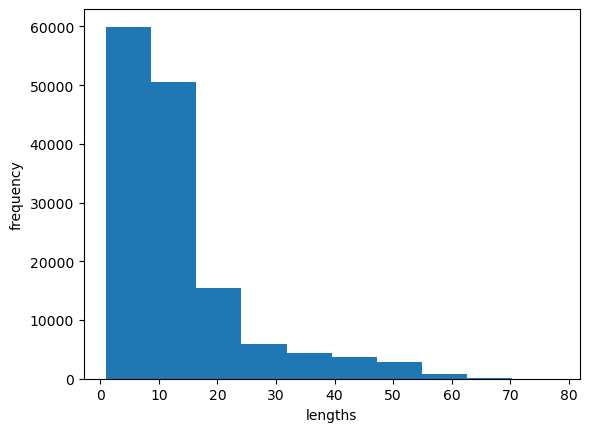

In [74]:
plt.figure()

plt.hist(lengths)

plt.xlabel("lengths")
plt.ylabel("frequency")
plt.show()

In [75]:
np.mean(lengths), np.min(lengths), np.max(lengths)

(13.234950577753027, 1, 78)

In [76]:
np.quantile(lengths, [0.25, 0.5, 0.75, 0.9])

array([ 6., 10., 16., 28.])

In [77]:
train_seq = pad_sequences(x_train, maxlen = 20)
test_seq = pad_sequences(x_test, maxlen = 20)

In [78]:
# 데이터 분할
sub_seq, val_seq, y_sub, y_val = train_test_split(train_seq, train_df["label"], test_size = 0.2,
                                                  stratify = train_df["label"], random_state = 26)

In [79]:
sub_seq.shape, val_seq.shape, y_sub.shape, y_val.shape

((114928, 20), (28732, 20), (114928,), (28732,))

In [80]:
test_seq.shape

(48403, 20)

# 모델 설계

In [83]:
model = keras.Sequential()
model.add(keras.Input(shape = (20,)))

model.add(keras.layers.Embedding(20000, 128))

model.add(keras.layers.GRU(64, dropout = 0.3, return_sequences = True))
model.add(keras.layers.GRU(128, dropout = 0.3))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Dense(128))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Dense(1, activation = "sigmoid"))

In [84]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 20, 128)             │       2,560,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_2 (GRU)                          │ (None, 20, 64)              │          37,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_3 (GRU)                          │ (None, 128)                 │          74,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,688,385 (10.26 MB)

 Trainable params: 2,688,385 (10.26 MB)

 Non-trainable params: 0 (0.00 B)

In [85]:
es = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [86]:
opt = keras.optimizers.Adam(learning_rate = 1e-4)

In [87]:
model.compile(optimizer = opt, loss = "binary_crossentropy", metrics = ["accuracy"])

In [88]:
history = model.fit(sub_seq, y_sub, epochs = 100, validation_data = (val_seq, y_val),
                    batch_size = 128, callbacks = [es])

Epoch 1/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 68s 68ms/step - accuracy: 0.6730 - loss: 0.5804 - val_accuracy: 0.8172 - val_loss: 0.3987
Epoch 2/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 56s 63ms/step - accuracy: 0.8379 - loss: 0.3715 - val_accuracy: 0.8377 - val_loss: 0.3702
Epoch 3/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 57s 63ms/step - accuracy: 0.8545 - loss: 0.3413 - val_accuracy: 0.8340 - val_loss: 0.3787
Epoch 4/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 57s 64ms/step - accuracy: 0.8620 - loss: 0.3287 - val_accuracy: 0.8392 - val_loss: 0.3703
Epoch 5/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 59s 66ms/step - accuracy: 0.8698 - loss: 0.3149 - val_accuracy: 0.8380 - val_loss: 0.3736
Epoch 6/100
898/898 ━━━━━━━━━━━━━━━━━━━━ 51s 56ms/step - accuracy: 0.8753 - loss: 0.3017 - val_accuracy: 0.8378 - val_loss: 0.3759
